<a href="https://colab.research.google.com/github/admirejanvier/admire/blob/main/Is%20Granola%20Healthy_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving healthy-food-survey-experts.csv to healthy-food-survey-experts.csv
Saving healthy-food-survey-public.csv to healthy-food-survey-public.csv


**Load and clean the data**
**Activity:**

o Load the public data.

o Display the dataframe.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
df_public = pd.read_csv('healthy-food-survey-public.csv')
df_public


,food,yes,no,no_opinion
0,almonds,913,55,24
1,apples,945,31,7
2,avocados,882,88,59
3,baked potatoes,666,248,26
4,butter,338,600,34
5,canned tuna,704,243,62
6,carrots,935,44,16
7,cashews,826,133,35
8,cheddar cheese,531,362,60
9,chicken,883,73,14


**percentage** of the public that considers each
**food healthy. **
**Activity:**

o Calculate the percentage of people who answered 'yes'.

o Round to the nearest percentage.

o Display the dataframe.



In [ ]:
df_public['public'] = df_public.eval('yes / (yes + no + no_opinion)')
df_public['public'] = df_public.eval('public * 100').round()
df_public #display

,food,yes,no,no_opinion,public
0,almonds,913,55,24,92.0
1,apples,945,31,7,96.0
2,avocados,882,88,59,86.0
3,baked potatoes,666,248,26,71.0
4,butter,338,600,34,35.0
5,canned tuna,704,243,62,70.0
6,carrots,935,44,16,94.0
7,cashews,826,133,35,83.0
8,cheddar cheese,531,362,60,56.0
9,chicken,883,73,14,91.0


**Activity:**
o Select the 'food' and 'public' columns from df_public.

o Assign the selected columns back to df_public.

o Display the result.


In [ ]:
df_public = df_public[['food', 'public']]
df_public #display

,food,public
0,almonds,92.0
1,apples,96.0
2,avocados,86.0
3,baked potatoes,71.0
4,butter,35.0
5,canned tuna,70.0
6,carrots,94.0
7,cashews,83.0
8,cheddar cheese,56.0
9,chicken,91.0


 -->Now let's load and clean the data from the experts, found in the 'healthy-foodsurvey-experts.csv' file.

--> Run the code below to perform the same data cleaning task for df_experts.

In [ ]:
df_experts = pd.read_csv('healthy-food-survey-experts.csv')
df_experts['experts'] = df_experts.eval('yes / (yes + no + no_opinion)')
df_experts['experts'] = df_experts.eval('experts * 100').round()
df_experts = df_experts[['food', 'experts']]
df_experts


,food,experts
0,almonds,98.0
1,apples,99.0
2,avocados,95.0
3,baked potatoes,72.0
4,butter,40.0
5,canned tuna,84.0
6,carrots,99.0
7,cashews,90.0
8,cheddar cheese,57.0
9,chicken,91.0


**Merge the datasets**
**Activity:**

o Use a left merge to combine the dataframes.

o Display the new dataframe.

In [ ]:
df = df_public.merge(df_experts, on='food', how='left')
df

,food,public,experts
0,almonds,92.0,98.0
1,apples,96.0,99.0
2,avocados,86.0,95.0
3,baked potatoes,71.0,72.0
4,butter,35.0,40.0
5,canned tuna,70.0,84.0
6,carrots,94.0,99.0
7,cashews,83.0,90.0
8,cheddar cheese,56.0,57.0
9,chicken,91.0,91.0


**Visualizing paired data**
**Activity:**
o Plot the paired-data.

o Label the axes.

o Add a title.

Text(0.5, 1.0, 'Is food healthy?')

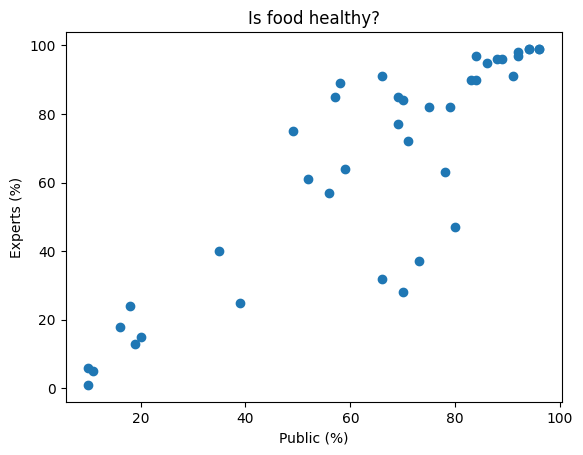

In [ ]:
plt.scatter(df['public'], df['experts'])
plt.xlabel('Public (%)')
plt.ylabel('Experts (%)')
plt.title('Is food healthy?')

**Add an equality line**
**Activity:**

o Plot an equality line from 0 to 100.

o Set the opacity to 50%.

o Use a dashed line style.

In [ ]:
def add_equality_line():
    x = [0, 50, 100]
    y = [0, 50, 100]

    plt.plot(x, y, color='black', alpha=0.5, linestyle='--')

**call it now**

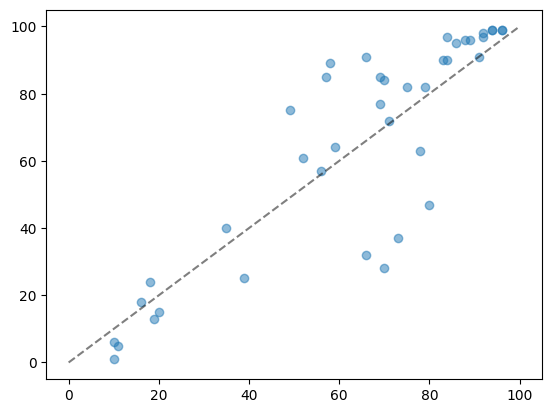

In [ ]:
plt.scatter(df['public'], df['experts'], alpha=0.5)

add_equality_line()

plt.show()

**Pro Tip 2: Square up the plot**

**Activity:**

o Limit x and y from 0 to 100.

o Make the aspect ratio equal.


In [ ]:
def square_the_plot():
    plt.xlim(0, 100)
    plt.ylim(0, 100)
    ax = plt.gca()
    ax.set_aspect(1)

**Then apply it to your scatter plot:**

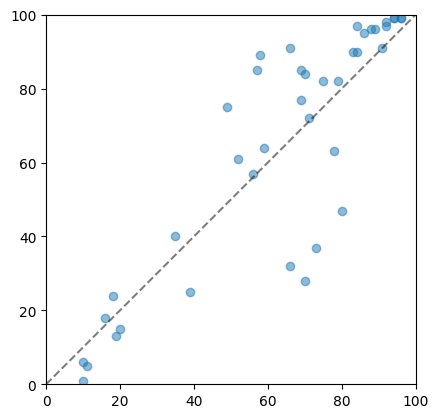

In [ ]:
plt.scatter(df['public'], df['experts'], alpha=0.5)

add_equality_line()
square_the_plot()

plt.show()

**Pro Tip 3: Change marker transparency**
**Activity: **
Make dots 50% transparent.

By reducing the transparency, it is
easier to distinguish overlapping
points

In [ ]:
def plot_data():
    plt.scatter(df['public'], df['experts'], alpha=0.5)

**

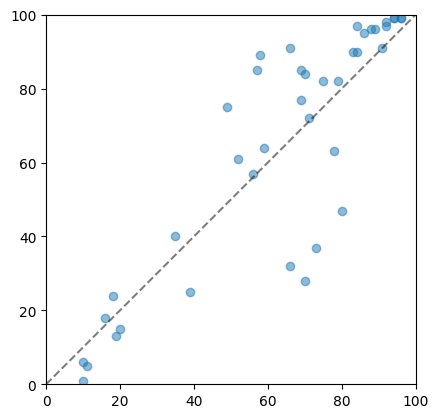

In [ ]:
plot_data()
add_equality_line()
square_the_plot()

plt.show()

**Combine all 3 Pro Tips**

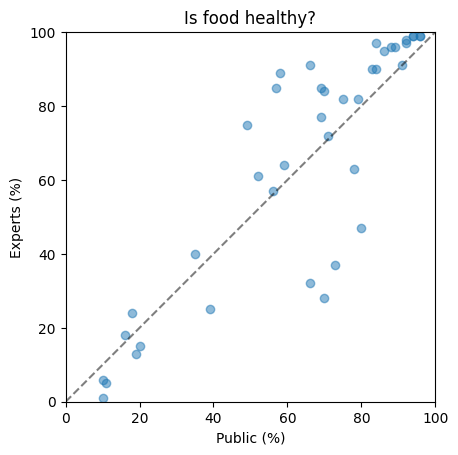

In [ ]:
def format_plot():
    plt.xlabel('Public (%)')
    plt.ylabel('Experts (%)')
    plt.title('Is food healthy?')
    plt.scatter(df['public'], df['experts'], alpha=0.5)

format_plot()
add_equality_line()
square_the_plot()

plt.show()

Identify foods with the greatest disagreement

In [ ]:
df['disagreement'] = abs(df['public'] - df['experts'])

highest_disagreement = df.nlargest(4, 'disagreement')

highest_disagreement

,food,public,experts,disagreement
19,granola bar,70.0,28.0,42.0
11,coconut oil,73.0,37.0,36.0
17,frozen yogurt,66.0,32.0,34.0
18,granola,80.0,47.0,33.0


Add labels to the scatter plot

In [ ]:
def add_labels(df, x_col, y_col, label_col):
    for (i, row) in df.iterrows():
        x = row[x_col]
        y = row[y_col]
        offset_spacing = " "
        label = offset_spacing + row[label_col]
        plt.text(x, y, label, va='center', ha='left')

Then run the complete visualization:

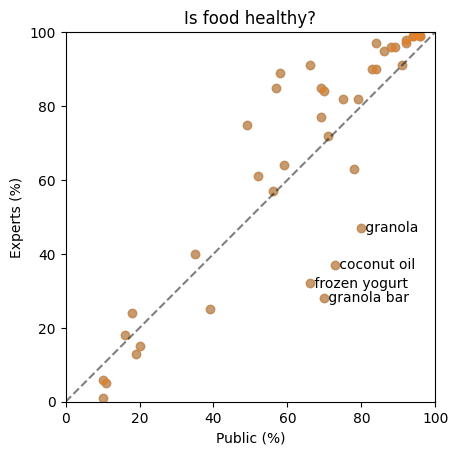

In [ ]:
plt.scatter(df['public'], df['experts'], alpha=0.5)

format_plot()
add_equality_line()
square_the_plot()

add_labels(highest_disagreement, 'public', 'experts', 'food')

plt.show()